# 🛒 E-commerce Sales Analysis with SQL — Azerbaijani Online Store
**Daily Data Analytics Project · Day 02**

## 1. Business question
An online retailer selling across 8 Azerbaijani cities (2024–2025) wants to know:
1. How are revenue, orders and average order value (AOV) trending, and how strong is seasonality?
2. Which categories make the **profit** — not just the revenue?
3. Why are some orders cancelled, and how much revenue does that cost?
4. How dependent is the business on its best customers, and do customers come back?

All analysis is done in **SQL (SQLite)** — CTEs, window functions (`LAG`, `RANK`, `NTILE`, running sums), `CASE` logic — with pandas/matplotlib only for display.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE, GREEN, RED, GREY = "#2E6FBA", "#E8833A", "#3A9D5D", "#C8453B", "#8A8F98"
IMG = Path("images"); IMG.mkdir(exist_ok=True)

con = sqlite3.connect("data/ecommerce.db")
def q(sql):
    return pd.read_sql_query(sql, con)

q("SELECT name, type FROM sqlite_master ORDER BY type, name")

,name,type
0,customers,table
1,order_items,table
2,orders_raw,table
3,products,table
4,orders,view
5,sales,view


## 2. Data quality check

In [2]:
q('''
SELECT 'customers' AS tbl, COUNT(*) AS n_rows FROM customers
UNION ALL SELECT 'products', COUNT(*) FROM products
UNION ALL SELECT 'orders_raw', COUNT(*) FROM orders_raw
UNION ALL SELECT 'order_items', COUNT(*) FROM order_items
''')

,tbl,n_rows
0,customers,6000
1,products,250
2,orders_raw,20972
3,order_items,35640


In [3]:
q('''
SELECT
  (SELECT COUNT(*) FROM orders_raw) - (SELECT COUNT(DISTINCT order_id) FROM orders_raw) AS duplicate_order_rows,
  (SELECT COUNT(*) FROM orders_raw WHERE delivery_days IS NULL)                         AS missing_delivery_days,
  (SELECT COUNT(*) FROM order_items i LEFT JOIN products p USING(product_id)
     WHERE p.product_id IS NULL)                                                       AS orphan_items,
  (SELECT COUNT(*) FROM orders_raw o LEFT JOIN customers c USING(customer_id)
     WHERE c.customer_id IS NULL)                                                      AS orphan_orders,
  (SELECT MIN(order_date) FROM orders_raw) AS first_order,
  (SELECT MAX(order_date) FROM orders_raw) AS last_order
''')

,duplicate_order_rows,missing_delivery_days,orphan_items,orphan_orders,first_order,last_order
0,25,40,0,0,2024-01-01,2025-12-31


**Cleaning:** 25 orders were loaded twice (exact duplicates) and 40 have no `delivery_days`. A clean `orders` view keeps one row per order and imputes missing delivery time with the city median. A `sales` view joins everything at line level and calculates net revenue (after discount) and gross profit.

In [4]:
con.executescript('''
DROP VIEW IF EXISTS orders;
CREATE VIEW orders AS
WITH dedup AS (SELECT DISTINCT * FROM orders_raw),
city_median AS (
  SELECT c.city, AVG(d.delivery_days) AS med
  FROM (SELECT o.*, c.city,
               ROW_NUMBER() OVER (PARTITION BY c.city ORDER BY o.delivery_days) AS rn,
               COUNT(*)     OVER (PARTITION BY c.city) AS cnt
        FROM dedup o JOIN customers c USING(customer_id)
        WHERE o.delivery_days IS NOT NULL) d
  JOIN customers c ON c.customer_id = d.customer_id
  WHERE d.rn IN ((d.cnt + 1) / 2, (d.cnt + 2) / 2)
  GROUP BY c.city
)
SELECT o.order_id, o.customer_id, o.order_date, o.status, o.payment_method,
       COALESCE(o.delivery_days, ROUND(m.med)) AS delivery_days
FROM dedup o
JOIN customers c USING(customer_id)
JOIN city_median m ON m.city = c.city;

DROP VIEW IF EXISTS sales;
CREATE VIEW sales AS
SELECT o.order_id, o.customer_id, o.order_date, strftime('%Y-%m', o.order_date) AS month,
       o.status, o.payment_method, o.delivery_days, c.city, c.acquisition_channel,
       p.category, p.product_name, i.quantity, i.discount,
       ROUND(i.quantity * i.unit_price * (1 - i.discount), 2)                    AS net_revenue,
       ROUND(i.quantity * (i.unit_price * (1 - i.discount) - p.unit_cost), 2)    AS gross_profit
FROM orders o
JOIN customers c   USING(customer_id)
JOIN order_items i USING(order_id)
JOIN products p    USING(product_id);
''')
q("SELECT COUNT(*) AS clean_orders, SUM(delivery_days IS NULL) AS still_missing FROM orders")

,clean_orders,still_missing
0,20948,0


## 3. Headline KPIs (delivered orders only)

In [5]:
kpi = q('''
SELECT COUNT(DISTINCT order_id)                         AS orders,
       COUNT(DISTINCT customer_id)                      AS customers,
       ROUND(SUM(net_revenue))                          AS revenue_azn,
       ROUND(SUM(gross_profit))                         AS gross_profit_azn,
       ROUND(100.0 * SUM(gross_profit) / SUM(net_revenue), 1) AS gross_margin_pct,
       ROUND(SUM(net_revenue) / COUNT(DISTINCT order_id), 1)  AS aov_azn
FROM sales WHERE status = 'Delivered'
''')
status = q('''
SELECT status, COUNT(*) AS orders, ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM orders GROUP BY status ORDER BY orders DESC
''')
display(kpi.T.rename(columns={0: "value"}), status)

,value
orders,"17,535.00"
customers,"5,328.00"
revenue_azn,"2,820,945.00"
gross_profit_azn,"751,531.00"
gross_margin_pct,26.60
aov_azn,160.90


,status,orders,pct
0,Delivered,17536,83.70
1,Cancelled,2373,11.30
2,Returned,1039,5.00


## 4. Monthly trend & seasonality — `LAG` and running totals

In [6]:
monthly = q('''
WITH m AS (
  SELECT month, SUM(net_revenue) AS revenue, COUNT(DISTINCT order_id) AS orders
  FROM sales WHERE status = 'Delivered' GROUP BY month
)
SELECT month, ROUND(revenue) AS revenue, orders, ROUND(revenue / orders, 1) AS aov,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY month)) / LAG(revenue) OVER (ORDER BY month), 1) AS mom_pct,
       ROUND(100.0 * (revenue - LAG(revenue, 12) OVER (ORDER BY month)) / LAG(revenue, 12) OVER (ORDER BY month), 1) AS yoy_pct,
       ROUND(SUM(revenue) OVER (PARTITION BY substr(month, 1, 4) ORDER BY month)) AS ytd_revenue
FROM m ORDER BY month
''')
monthly

,month,revenue,orders,aov,mom_pct,yoy_pct,ytd_revenue
0,2024-01,"45,902.00",280,163.90,NaN,NaN,"45,902.00"
1,2024-02,"46,487.00",265,175.40,1.30,NaN,"92,389.00"
2,2024-03,"94,099.00",570,165.10,102.40,NaN,"186,487.00"
3,2024-04,"60,468.00",375,161.20,-35.70,NaN,"246,955.00"
4,2024-05,"68,962.00",398,173.30,14.00,NaN,"315,917.00"
5,2024-06,"65,148.00",394,165.40,-5.50,NaN,"381,065.00"
6,2024-07,"67,173.00",422,159.20,3.10,NaN,"448,238.00"
7,2024-08,"64,176.00",424,151.40,-4.50,NaN,"512,415.00"
8,2024-09,"87,515.00",574,152.50,36.40,NaN,"599,929.00"
9,2024-10,"95,288.00",581,164.00,8.90,NaN,"695,217.00"


In [7]:
yearly = q('''
SELECT substr(month,1,4) AS year, ROUND(SUM(net_revenue)) AS revenue,
       COUNT(DISTINCT order_id) AS orders, ROUND(SUM(net_revenue)/COUNT(DISTINCT order_id),1) AS aov
FROM sales WHERE status='Delivered' GROUP BY year
''')
yearly["growth_pct"] = (yearly["revenue"].pct_change() * 100).round(1)
yearly

,year,revenue,orders,aov,growth_pct
0,2024,"1,007,967.00",6382,157.90,NaN
1,2025,"1,812,979.00",11153,162.60,79.90


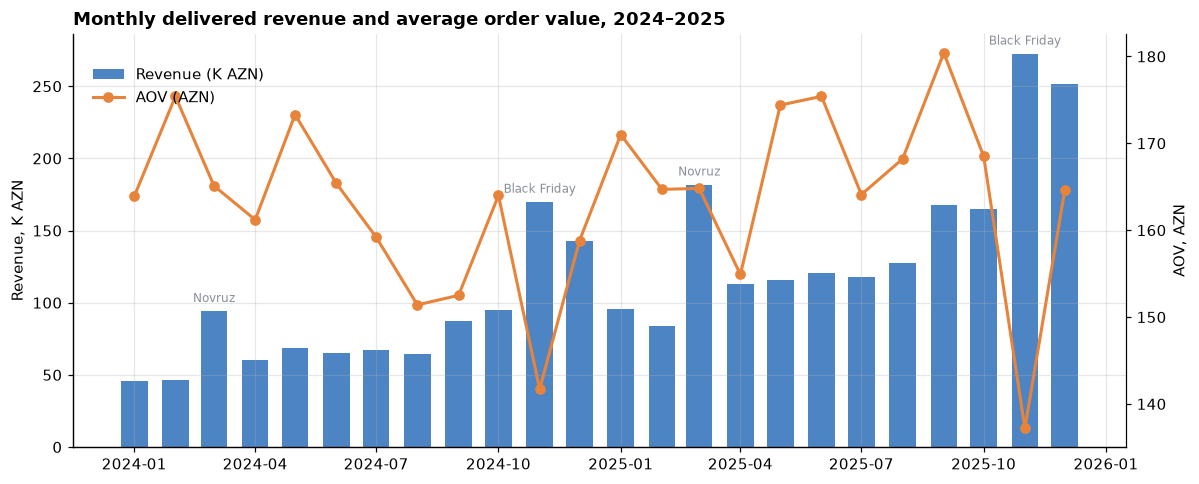

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = pd.to_datetime(monthly["month"])
ax.bar(x, monthly["revenue"] / 1000, width=20, color=BLUE, alpha=0.85, label="Revenue (K AZN)")
ax.set_ylabel("Revenue, K AZN")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(x, monthly["aov"], color=ORANGE, marker="o", lw=2, label="AOV (AZN)")
ax2.set_ylabel("AOV, AZN"); ax2.spines["right"].set_visible(True)
for m, lab in [("2024-03", "Novruz"), ("2024-11", "Black Friday"), ("2025-03", "Novruz"), ("2025-11", "Black Friday")]:
    r = monthly[monthly["month"] == m].iloc[0]
    ax.annotate(lab, (pd.to_datetime(m), r["revenue"] / 1000), xytext=(0, 6), textcoords="offset points",
                ha="center", fontsize=8, color=GREY)
ax.set_title("Monthly delivered revenue and average order value, 2024–2025", loc="left", fontweight="bold")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88), frameon=False)
fig.tight_layout(); fig.savefig(IMG / "monthly_trend.png", bbox_inches="tight"); plt.show()

## 5. Category profitability — revenue vs. margin

In [9]:
cat = q('''
SELECT category,
       ROUND(SUM(net_revenue)) AS revenue,
       ROUND(SUM(gross_profit)) AS gross_profit,
       ROUND(100.0 * SUM(gross_profit) / SUM(net_revenue), 1) AS margin_pct,
       ROUND(100.0 * SUM(net_revenue)  / SUM(SUM(net_revenue))  OVER (), 1) AS revenue_share_pct,
       ROUND(100.0 * SUM(gross_profit) / SUM(SUM(gross_profit)) OVER (), 1) AS profit_share_pct,
       ROUND(AVG(discount) * 100, 1) AS avg_discount_pct
FROM sales WHERE status = 'Delivered'
GROUP BY category ORDER BY gross_profit DESC
''')
cat

,category,revenue,gross_profit,margin_pct,revenue_share_pct,profit_share_pct,avg_discount_pct
0,Fashion,"739,299.00","341,257.00",46.20,26.20,45.40,7.70
1,Beauty,"239,738.00","125,265.00",52.30,8.50,16.70,7.70
2,Home & Kitchen,"403,019.00","111,363.00",27.60,14.30,14.80,7.60
3,Kids & Toys,"260,167.00","87,351.00",33.60,9.20,11.60,7.50
4,Electronics,"1,092,190.00","79,393.00",7.30,38.70,10.60,7.90
5,Groceries,"86,532.00","6,901.00",8.00,3.10,0.90,7.60


In [10]:
top_products = q('''
WITH p AS (
  SELECT category, product_name, SUM(net_revenue) AS revenue, SUM(gross_profit) AS profit
  FROM sales WHERE status = 'Delivered' GROUP BY category, product_name
)
SELECT * FROM (
  SELECT category, product_name, ROUND(revenue) AS revenue, ROUND(profit) AS profit,
         RANK() OVER (PARTITION BY category ORDER BY profit DESC) AS rank_in_category
  FROM p)
WHERE rank_in_category <= 2 ORDER BY profit DESC
''')
top_products

,category,product_name,revenue,profit,rank_in_category
0,Fashion,Fashion-060,"80,408.00","43,860.00",1
1,Fashion,Fashion-048,"69,710.00","35,614.00",2
2,Beauty,Beauty-003,"36,353.00","20,567.00",1
3,Beauty,Beauty-024,"35,951.00","18,455.00",2
4,Electronics,Electronics-018,"254,456.00","16,591.00",1
5,Home & Kitchen,Home-021,"48,776.00","16,268.00",1
6,Home & Kitchen,Home-001,"62,199.00","14,136.00",2
7,Kids & Toys,Kids-029,"37,268.00","12,492.00",1
8,Kids & Toys,Kids-003,"30,085.00","11,194.00",2
9,Electronics,Electronics-020,"89,929.00","9,935.00",2


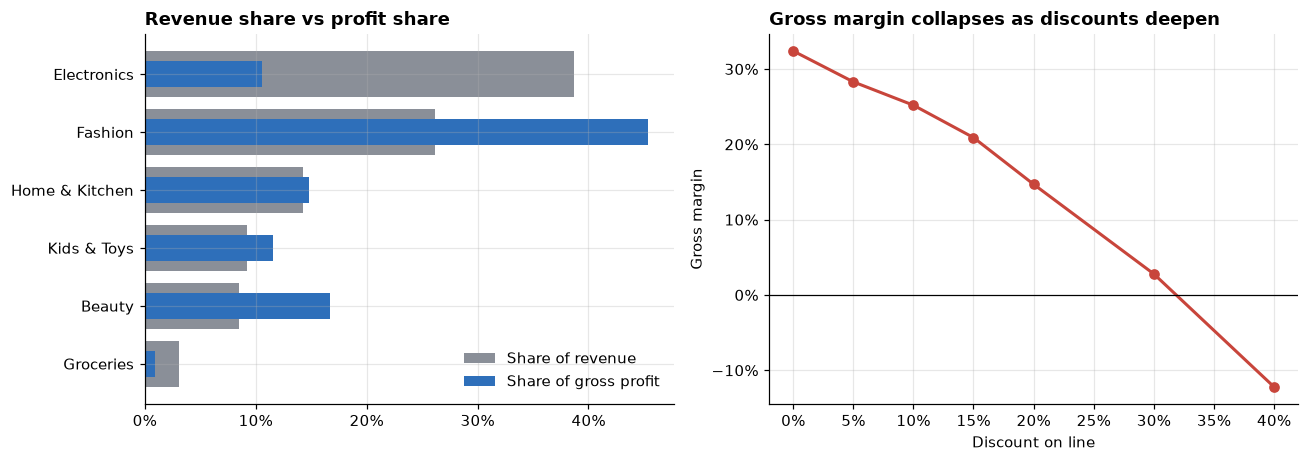

,discount_pct,margin_pct,lines
0,0,32.40,15084
1,5,28.30,3998
2,10,25.20,3349
3,15,20.90,2116
4,20,14.70,2410
5,30,2.80,2028
6,40,-12.20,865


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
c = cat.sort_values("revenue")
axes[0].barh(c["category"], c["revenue_share_pct"], color=GREY, label="Share of revenue")
axes[0].barh(c["category"], c["profit_share_pct"], color=BLUE, height=0.45, label="Share of gross profit")
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[0].legend(frameon=False, loc="lower right")
axes[0].set_title("Revenue share vs profit share", loc="left", fontweight="bold")
disc = q('''
SELECT CAST(discount*100 AS INT) AS discount_pct,
       ROUND(100.0 * SUM(gross_profit) / SUM(net_revenue), 1) AS margin_pct,
       COUNT(*) AS lines
FROM sales WHERE status='Delivered' GROUP BY discount_pct ORDER BY discount_pct
''')
axes[1].plot(disc["discount_pct"], disc["margin_pct"], marker="o", color=RED, lw=2)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[1].set_xlabel("Discount on line"); axes[1].set_ylabel("Gross margin")
axes[1].set_title("Gross margin collapses as discounts deepen", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(IMG / "category_profit_discount.png", bbox_inches="tight"); plt.show()
disc

## 6. Cancellations — payment method, delivery time and city

In [12]:
cancel_pay = q('''
SELECT payment_method, COUNT(*) AS orders,
       ROUND(100.0 * AVG(status = 'Cancelled'), 1) AS cancel_rate_pct,
       ROUND(100.0 * AVG(status = 'Returned'), 1)  AS return_rate_pct
FROM orders GROUP BY payment_method ORDER BY cancel_rate_pct DESC
''')
cancel_city = q('''
SELECT s.city, COUNT(DISTINCT s.order_id) AS orders,
       ROUND(AVG(o.delivery_days), 1) AS avg_delivery_days,
       ROUND(100.0 * COUNT(DISTINCT CASE WHEN s.status='Cancelled' THEN s.order_id END) / COUNT(DISTINCT s.order_id), 1) AS cancel_rate_pct,
       ROUND(SUM(CASE WHEN s.status='Delivered' THEN s.net_revenue ELSE 0 END)) AS delivered_revenue,
       ROUND(SUM(CASE WHEN s.status='Cancelled' THEN s.net_revenue ELSE 0 END)) AS cancelled_revenue
FROM sales s JOIN orders o USING(order_id)
GROUP BY s.city ORDER BY orders DESC
''')
display(cancel_pay, cancel_city)

,payment_method,orders,cancel_rate_pct,return_rate_pct
0,Cash on delivery,7329,16.90,5.20
1,Card,11563,8.40,4.70
2,BNPL,2056,7.80,5.30


,city,orders,avg_delivery_days,cancel_rate_pct,delivered_revenue,cancelled_revenue
0,Baku,11951,2.50,8.90,"1,665,196.00","154,342.00"
1,Sumgait,2149,3.40,11.50,"301,624.00","38,158.00"
2,Ganja,1677,4.50,14.80,"217,875.00","38,263.00"
3,Sheki,1157,6.50,17.70,"136,798.00","32,077.00"
4,Mingachevir,1107,5.30,14.20,"139,886.00","24,382.00"
5,Lankaran,1030,6.50,16.70,"131,832.00","23,215.00"
6,Guba,951,5.50,15.90,"110,780.00","24,912.00"
7,Shirvan,925,5.50,13.90,"116,978.00","20,088.00"


In [13]:
cancel_delivery = q('''
SELECT CASE WHEN delivery_days <= 1 THEN '1 day' WHEN delivery_days <= 3 THEN '2–3 days'
            WHEN delivery_days <= 5 THEN '4–5 days' ELSE '6+ days' END AS delivery_bucket,
       COUNT(*) AS orders, ROUND(100.0 * AVG(status = 'Cancelled'), 1) AS cancel_rate_pct
FROM orders GROUP BY delivery_bucket ORDER BY MIN(delivery_days)
''')
lost = q('''
SELECT ROUND(SUM(net_revenue)) AS cancelled_revenue,
       ROUND(100.0 * SUM(net_revenue) / (SELECT SUM(net_revenue) FROM sales WHERE status IN ('Delivered','Cancelled')), 1) AS pct_of_demand,
       ROUND(SUM(CASE WHEN payment_method='Cash on delivery' THEN net_revenue END)) AS cod_cancelled_revenue
FROM sales WHERE status = 'Cancelled'
''')
display(cancel_delivery, lost)

,delivery_bucket,orders,cancel_rate_pct
0,1 day,3598,6.30
1,2–3 days,7400,9.30
2,4–5 days,6348,13.40
3,6+ days,3602,16.90


,cancelled_revenue,pct_of_demand,cod_cancelled_revenue
0,"355,437.00",11.20,"185,336.00"


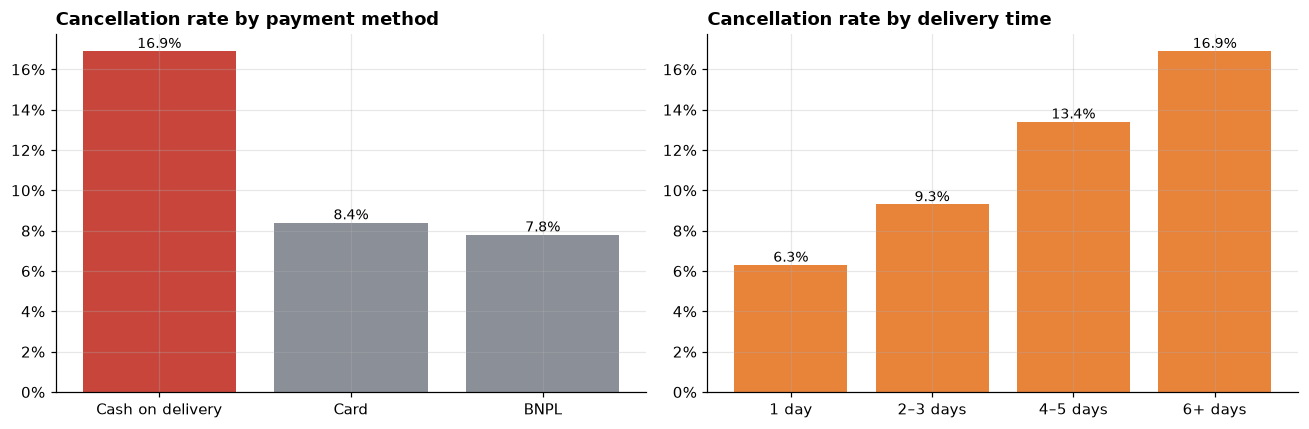

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(cancel_pay["payment_method"], cancel_pay["cancel_rate_pct"],
            color=[RED if m == "Cash on delivery" else GREY for m in cancel_pay["payment_method"]])
axes[0].set_title("Cancellation rate by payment method", loc="left", fontweight="bold")
axes[1].bar(cancel_delivery["delivery_bucket"], cancel_delivery["cancel_rate_pct"], color=ORANGE)
axes[1].set_title("Cancellation rate by delivery time", loc="left", fontweight="bold")
for a, d in zip(axes, [cancel_pay, cancel_delivery]):
    a.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    for p in a.patches:
        a.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom", fontsize=9)
fig.tight_layout(); fig.savefig(IMG / "cancellation_drivers.png", bbox_inches="tight"); plt.show()

## 7. Customer concentration & repeat purchases — `NTILE` and cumulative share

In [15]:
deciles = q('''
WITH cust AS (
  SELECT customer_id, SUM(net_revenue) AS revenue, COUNT(DISTINCT order_id) AS orders
  FROM sales WHERE status = 'Delivered' GROUP BY customer_id
), d AS (SELECT *, NTILE(10) OVER (ORDER BY revenue DESC) AS decile FROM cust)
SELECT decile, COUNT(*) AS customers, ROUND(SUM(revenue)) AS revenue,
       ROUND(AVG(orders), 1) AS avg_orders,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS revenue_share_pct,
       ROUND(100.0 * SUM(SUM(revenue)) OVER (ORDER BY decile) / SUM(SUM(revenue)) OVER (), 1) AS cumulative_pct
FROM d GROUP BY decile ORDER BY decile
''')
deciles

,decile,customers,revenue,avg_orders,revenue_share_pct,cumulative_pct
0,1,533,"1,194,131.00",9.30,42.30,42.30
1,2,533,"576,785.00",5.80,20.40,62.80
2,3,533,"366,059.00",4.20,13.00,75.80
3,4,533,"244,628.00",3.50,8.70,84.40
4,5,533,"166,169.00",2.70,5.90,90.30
5,6,533,"114,314.00",2.10,4.10,94.40
6,7,533,"75,978.00",1.70,2.70,97.10
7,8,533,"47,891.00",1.40,1.70,98.80
8,9,532,"25,797.00",1.20,0.90,99.70
9,10,532,"9,194.00",1.10,0.30,100.00


In [16]:
repeat = q('''
WITH c AS (SELECT customer_id, COUNT(*) AS n FROM orders WHERE status='Delivered' GROUP BY customer_id)
SELECT COUNT(*) AS buyers,
       ROUND(100.0 * AVG(n >= 2), 1) AS repeat_rate_pct,
       ROUND(AVG(n), 2) AS orders_per_buyer
FROM c
''')
gap = q('''
WITH o AS (
  SELECT customer_id, order_date,
         ROW_NUMBER() OVER (PARTITION BY customer_id ORDER BY order_date) AS nth,
         julianday(order_date) - julianday(LAG(order_date) OVER (PARTITION BY customer_id ORDER BY order_date)) AS gap_days
  FROM orders WHERE status = 'Delivered'
)
SELECT ROUND(AVG(CASE WHEN nth = 2 THEN gap_days END)) AS avg_days_1st_to_2nd,
       ROUND(AVG(gap_days)) AS avg_days_between_orders
FROM o
''')
channel = q('''
WITH c AS (
  SELECT s.customer_id, s.acquisition_channel, COUNT(DISTINCT s.order_id) AS n, SUM(s.net_revenue) AS rev
  FROM sales s WHERE status='Delivered' GROUP BY s.customer_id, s.acquisition_channel
)
SELECT acquisition_channel, COUNT(*) AS buyers, ROUND(100.0*AVG(n>=2),1) AS repeat_rate_pct,
       ROUND(AVG(rev)) AS revenue_per_buyer
FROM c GROUP BY acquisition_channel ORDER BY revenue_per_buyer DESC
''')
display(repeat, gap, channel)

,buyers,repeat_rate_pct,orders_per_buyer
0,5328,60.80,3.29


,avg_days_1st_to_2nd,avg_days_between_orders
0,131.00,90.00


,acquisition_channel,buyers,repeat_rate_pct,revenue_per_buyer
0,Referral,520,66.00,649.00
1,Organic,1360,61.00,530.00
2,Google Ads,1024,59.80,526.00
3,Instagram,1695,59.70,507.00
4,TikTok,729,60.40,501.00


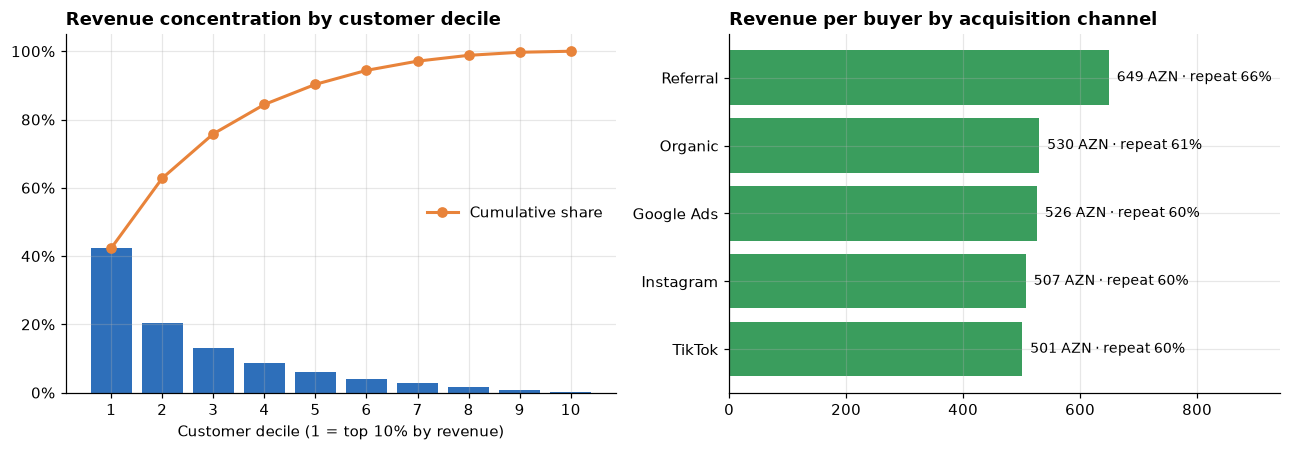

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(deciles["decile"], deciles["revenue_share_pct"], color=BLUE)
axes[0].plot(deciles["decile"], deciles["cumulative_pct"], color=ORANGE, marker="o", lw=2, label="Cumulative share")
axes[0].set_xticks(deciles["decile"]); axes[0].set_xlabel("Customer decile (1 = top 10% by revenue)")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[0].legend(frameon=False, loc="center right")
axes[0].set_title("Revenue concentration by customer decile", loc="left", fontweight="bold")
ch = channel.sort_values("revenue_per_buyer")
axes[1].barh(ch["acquisition_channel"], ch["revenue_per_buyer"], color=GREEN)
for i, (v, r) in enumerate(zip(ch["revenue_per_buyer"], ch["repeat_rate_pct"])):
    axes[1].text(v, i, f"  {v:,.0f} AZN · repeat {r:.0f}%", va="center", fontsize=9)
axes[1].set_xlim(0, ch["revenue_per_buyer"].max() * 1.45)
axes[1].set_title("Revenue per buyer by acquisition channel", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(IMG / "customer_concentration.png", bbox_inches="tight"); plt.show()

## 8. Findings & recommendations

In [18]:
c24, c25 = yearly["revenue"].tolist()
cod = cancel_pay.set_index("payment_method")["cancel_rate_pct"]
top = cat.iloc[0]; elec = cat.set_index("category").loc["Electronics"]
findings = pd.DataFrame([
    ["Growth", f"Revenue {c24:,.0f} → {c25:,.0f} AZN ({yearly['growth_pct'].iloc[1]:+.1f}% YoY); Nov–Dec are the peak months",
     "Plan stock, couriers and ad budget for Novruz, Black Friday and New Year 6–8 weeks ahead"],
    ["Profit mix", f"Electronics = {elec['revenue_share_pct']}% of revenue but only {elec['profit_share_pct']}% of profit ({elec['margin_pct']}% margin); "
                   f"{top['category']} leads profit ({top['profit_share_pct']}%)",
     "Shift promotion spend toward high-margin Fashion & Beauty; use Electronics as traffic driver, not discount target"],
    ["Discounts", f"Lines at 30%+ discount run at {disc.loc[disc['discount_pct']>=30,'margin_pct'].iloc[0]}% margin vs {disc.loc[disc['discount_pct']==0,'margin_pct'].iloc[0]}% at full price",
     "Cap discounts at 20% outside Black Friday; exclude low-margin Electronics/Groceries from deep promos"],
    ["Cancellations", f"Cash on delivery cancels at {cod['Cash on delivery']}% vs {cod['Card']}% for card; {lost['cancelled_revenue'][0]:,.0f} AZN lost",
     "Offer a small card-payment incentive / prepaid deposit for COD orders above a threshold"],
    ["Delivery", f"Cancel rate rises from {cancel_delivery['cancel_rate_pct'].iloc[0]}% (1 day) to {cancel_delivery['cancel_rate_pct'].iloc[-1]}% (6+ days)",
     "Add regional pickup points / partner couriers in Lankaran, Sheki, Ganja"],
    ["Loyalty", f"Top 10% of buyers = {deciles['revenue_share_pct'].iloc[0]}% of revenue; repeat rate {repeat['repeat_rate_pct'][0]}%",
     "Launch a VIP tier for the top decile and a 2nd-order coupon timed ~{:.0f} days after first purchase".format(gap['avg_days_1st_to_2nd'][0])],
], columns=["Area", "Finding", "Recommendation"])
findings.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

Area,Finding,Recommendation
Growth,"Revenue 1,007,967 → 1,812,979 AZN (+79.9% YoY); Nov–Dec are the peak months","Plan stock, couriers and ad budget for Novruz, Black Friday and New Year 6–8 weeks ahead"
Profit mix,Electronics = 38.7% of revenue but only 10.6% of profit (7.3% margin); Fashion leads profit (45.4%),"Shift promotion spend toward high-margin Fashion & Beauty; use Electronics as traffic driver, not discount target"
Discounts,Lines at 30%+ discount run at 2.8% margin vs 32.4% at full price,Cap discounts at 20% outside Black Friday; exclude low-margin Electronics/Groceries from deep promos
Cancellations,"Cash on delivery cancels at 16.9% vs 8.4% for card; 355,437 AZN lost",Offer a small card-payment incentive / prepaid deposit for COD orders above a threshold
Delivery,Cancel rate rises from 6.3% (1 day) to 16.9% (6+ days),"Add regional pickup points / partner couriers in Lankaran, Sheki, Ganja"
Loyalty,Top 10% of buyers = 42.3% of revenue; repeat rate 60.8%,Launch a VIP tier for the top decile and a 2nd-order coupon timed ~131 days after first purchase


In [19]:
con.close()